# ArcFace Results Summary

Aggregate `arcface.json` using the same final-epoch test accuracy summary as
`deep_qda_covariances_table.ipynb`. The table reports **mean ± population standard
deviation in percent** across all stored runs for each dataset. Every run is
included, including runs near chance accuracy. No best-epoch selection is used.

The CIFAR-10 and CIFAR-100 plots show mean training and test accuracy across
runs and are exported as `arcface_curves.png` at **600 dpi**. Accuracies use the
margin-free cosine classifier recorded by the training script.


In [1]:
import json
from pathlib import Path
import statistics as stats

import pandas as pd

candidates = [
    Path('arcface.json'),
    Path('results/arcface.json'),
    Path('simplex-lda/results/arcface.json'),
]
json_path = next((p for p in candidates if p.is_file()), None)
if json_path is None:
    raise FileNotFoundError('Cannot find arcface.json')
with json_path.open('r', encoding='utf-8') as f:
    data = json.load(f)


In [2]:
results = data['results']
rows = []
run_rows = []
for dataset_name, methods in results.items():
    for method, runs in methods.items():
        final_test = [run['final_test_acc'] for run in runs]
        rows.append({
            'dataset': dataset_name,
            'method': method,
            'mean_test': stats.mean(final_test),
            'std_test': stats.pstdev(final_test),
            'runs': len(final_test),
        })
        for run in runs:
            run_rows.append({
                'dataset': dataset_name,
                'method': method,
                'run': run['run'],
                'seed': run.get('seed'),
                'final_train_acc_percent': 100 * run['final_train_acc'],
                'final_test_acc_percent': 100 * run['final_test_acc'],
            })

# Keep unrounded values available for further analysis and individual-run review.
df = pd.DataFrame(rows)
run_df = pd.DataFrame(run_rows)
method_order = ['arcface']
dataset_order = ['FashionMNIST', 'CIFAR10', 'CIFAR100']
df['summary'] = df.apply(
    lambda r: f"{r['mean_test'] * 100:.2f} ± {r['std_test'] * 100:.2f}", axis=1
)
table = df.pivot(index='method', columns='dataset', values='summary')
table = table.reindex(index=method_order, columns=dataset_order)
table = table.rename(index={'arcface': 'ArcFace'})
table.index.name = 'Method'
table.columns.name = 'Dataset'
table


Dataset,FashionMNIST,CIFAR10,CIFAR100
Method,,,
ArcFace,93.17 ± 0.17,36.52 ± 37.51,1.01 ± 0.01


## CIFAR-10 and CIFAR-100 Accuracy Curves

Mean training and test accuracy across all runs. Solid lines show training
accuracy; dashed lines show test accuracy. Values are percentages, with one
decimal place on the vertical ticks. Individual final accuracies and seeds are
available in `run_df`; numeric summary statistics and run counts are in `df`.


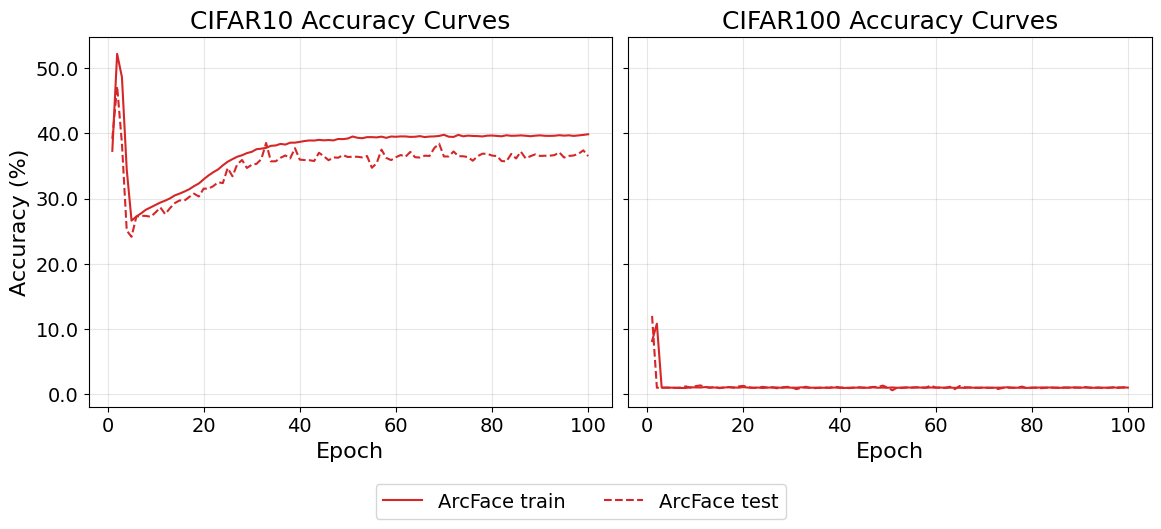

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'legend.fontsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})

def build_mean_curve(dataset_name):
    rows = []
    for method, runs in data['results'][dataset_name].items():
        for run in runs:
            for metrics in run['epoch_metrics']:
                rows.append({
                    'method': method,
                    'epoch': metrics['epoch'],
                    'train_acc': metrics['train_acc'],
                    'test_acc': metrics['test_acc'],
                })
    curve_df = pd.DataFrame(rows)
    return (
        curve_df.groupby(['method', 'epoch'])[['train_acc', 'test_acc']]
        .mean().reset_index()
    )

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True, constrained_layout=True)
for ax, dataset_name in zip(axes, ['CIFAR10', 'CIFAR100']):
    mean_curve = build_mean_curve(dataset_name)
    subset = mean_curve[mean_curve['method'] == 'arcface']
    ax.plot(subset['epoch'], subset['train_acc'] * 100,
            color='#d62728', linestyle='-', label='ArcFace train')
    ax.plot(subset['epoch'], subset['test_acc'] * 100,
            color='#d62728', linestyle='--', label='ArcFace test')
    ax.set_title(f'{dataset_name} Accuracy Curves')
    ax.set_xlabel('Epoch')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Accuracy (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02),
           frameon=True, ncol=2)
plot_path = json_path.with_name('arcface_curves.png')
fig.savefig(plot_path, dpi=600, bbox_inches='tight', pad_inches=0.1)
plt.show()
